# Lesson 1 — The game and what the agent sees

In this lesson you learn:

1. How the code stores the Tetris board.
2. The **4 numbers** (features) that the agent sees.
3. The possible moves (**actions**) and the board after each move (**afterstates**).
4. The **reward**: how the game tells the agent "good" or "bad".

**How to use this notebook:** run each cell in order with **Shift + Enter**.
Read the text, then change the code and run it again. You cannot break anything.

Source file for this lesson: `src/tetris.py`.

---

**🇻🇳 Bài 1 — Trò chơi và những gì agent nhìn thấy**

Trong bài này bạn học:

1. Code lưu bàn chơi Tetris như thế nào.
2. **4 con số** (đặc trưng — features) mà agent (chương trình ra quyết định) nhìn thấy.
3. Các nước đi có thể có (**actions**) và bàn chơi sau mỗi nước đi (**afterstates**).
4. **Phần thưởng (reward)**: cách trò chơi báo cho agent biết "tốt" hay "xấu".

**Cách dùng notebook:** chạy từng ô theo thứ tự bằng **Shift + Enter**.
Đọc phần chữ, sau đó sửa code và chạy lại. Bạn không thể làm hỏng gì cả.

File mã nguồn của bài này: `src/tetris.py`.

In [1]:
# Setup: find the project folder, so that "import src..." works from this notebook.
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
print("Project folder:", ROOT)

Project folder: /Users/phuonghqh/Documents/working/Tetris-deep-Q-learning-pytorch


In [2]:
import random
import numpy as np
from src.tetris import Tetris
from nb_utils import (draw_board, draw_boards, board_from_text, features_text, afterstates,
                      evaluate, random_policy, PIECE_NAMES, FEATURE_NAMES)

## Part 1 — The board

The board is a list of 20 rows. Each row is a list of 10 numbers.

- `0` = an empty cell
- `1` to `7` = a block of one piece type (the number sets the color)

---

**🇻🇳 Phần 1 — Bàn chơi**

Bàn chơi là một danh sách gồm 20 hàng. Mỗi hàng là một danh sách gồm 10 số.

- `0` = ô trống
- `1` đến `7` = một khối của một loại mảnh (con số quyết định màu)

rows: 20 | columns: 10
top row: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


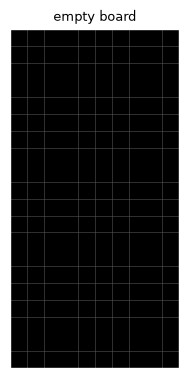

In [3]:
env = Tetris(width=10, height=20, block_size=30)
env.reset()
print("rows:", len(env.board), "| columns:", len(env.board[0]))
print("top row:", env.board[0])
draw_board(env.board, title="empty board");

### The 7 pieces

`Tetris.pieces` stores each piece as a small grid of numbers.

---

**🇻🇳 7 loại mảnh**

`Tetris.pieces` lưu mỗi mảnh dưới dạng một lưới số nhỏ.

O: [[1, 1], [1, 1]]
T: [[0, 2, 0], [2, 2, 2]]
S: [[0, 3, 3], [3, 3, 0]]
Z: [[4, 4, 0], [0, 4, 4]]
I: [[5, 5, 5, 5]]
L: [[0, 0, 6], [6, 6, 6]]
J: [[7, 0, 0], [7, 7, 7]]


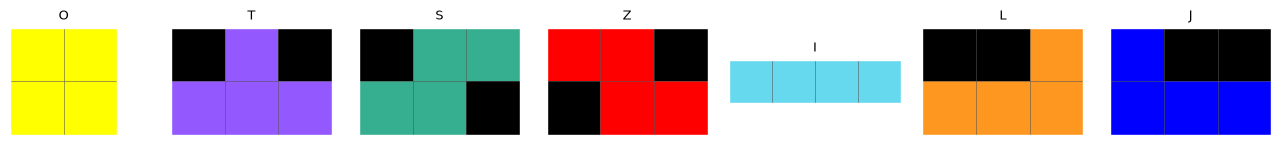

In [4]:
for name, piece in zip(PIECE_NAMES, Tetris.pieces):
    print(f"{name}: {piece}")
draw_boards(Tetris.pieces, titles=PIECE_NAMES, cols=7)

### Rotation

`env.rotate(piece)` turns a piece 90° clockwise. Below: the T piece after 0, 1, 2 and 3 turns.

---

**🇻🇳 Xoay**

`env.rotate(piece)` xoay mảnh 90° theo chiều kim đồng hồ. Bên dưới: mảnh T sau 0, 1, 2 và 3 lần xoay.

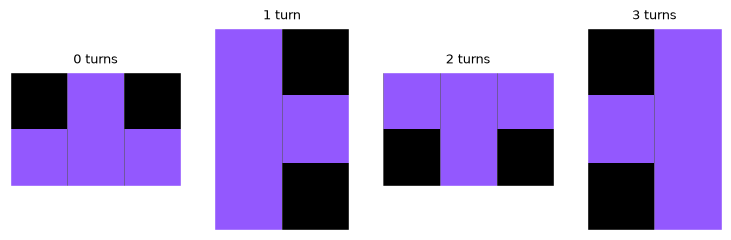

In [5]:
shapes = [Tetris.pieces[1]]
for _ in range(3):
    shapes.append(env.rotate(shapes[-1]))
draw_boards(shapes, titles=["0 turns", "1 turn", "2 turns", "3 turns"], cols=4)

## Part 2 — The 4 numbers that the agent sees (the state)

The agent does **not** see the 200 cells. `get_state_properties()` changes a board into 4 numbers:

| Feature | Meaning | Good or bad |
|---|---|---|
| `lines_cleared` | full rows that this move removes | high is good |
| `holes` | empty cells with a block above them | high is bad |
| `bumpiness` | sum of the height differences between neighbor columns | high is bad |
| `height` | sum of the heights of all 10 columns | high is bad |

**Exercise:** look at the board below. Before you run the next cells, guess the 4 numbers.

---

**🇻🇳 Phần 2 — 4 con số mà agent nhìn thấy (trạng thái — state)**

Agent **không** nhìn 200 ô. `get_state_properties()` biến một bàn chơi thành 4 con số:

| Đặc trưng | Ý nghĩa | Tốt hay xấu |
|---|---|---|
| `lines_cleared` | số hàng đầy mà nước đi này xóa | cao là tốt |
| `holes` | ô trống có khối nằm phía trên | cao là xấu |
| `bumpiness` | tổng chênh lệch chiều cao giữa các cột cạnh nhau | cao là xấu |
| `height` | tổng chiều cao của cả 10 cột | cao là xấu |

**Bài tập:** nhìn bàn chơi bên dưới. Trước khi chạy các ô tiếp theo, hãy đoán 4 con số.

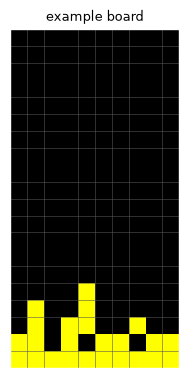

In [6]:
board = board_from_text('''
..........
....#.....
.#..#.....
.#.##..#..
##.#.##.##
##########
''')
draw_board(board, title="example board");

In [7]:
features = env.get_state_properties([row[:] for row in board])   # give a copy: the function can change the list
for name, value in zip(FEATURE_NAMES, features.tolist()):
    print(f"{name:>14}: {value:.0f}")

 lines_cleared: 1
         holes: 2
     bumpiness: 14
        height: 16


### How the code gets these numbers

**Important:** the code first removes the full rows. Then it measures the board that is left.

---

**🇻🇳 Code tính các con số này như thế nào**

**Quan trọng:** code xóa các hàng đầy trước. Sau đó code đo phần bàn chơi còn lại.

lines cleared   : 1
column heights  : [1, 3, 0, 2, 4, 1, 1, 2, 1, 1] -> height = 16
neighbor diffs  : [2, 3, 2, 2, 3, 0, 1, 1, 0] -> bumpiness = 14
holes           : 2


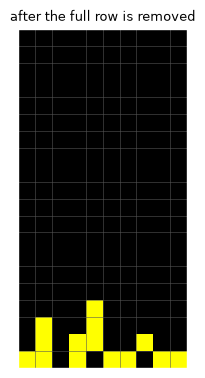

In [8]:
lines, cleared = env.check_cleared_rows([row[:] for row in board])
heights = [20 - next((r for r in range(20) if cleared[r][c]), 20) for c in range(10)]
diffs = [abs(a - b) for a, b in zip(heights, heights[1:])]

print("lines cleared   :", lines)
print("column heights  :", heights, "-> height =", sum(heights))
print("neighbor diffs  :", diffs, "-> bumpiness =", sum(diffs))
print("holes           :", env.get_holes(cleared))
draw_board(cleared, title="after the full row is removed");

**Exercise:** change the text board above. Add a hole, or fill one more row. Then run the 3 cells again.
Do the numbers change as you expect?

---

🇻🇳 **Bài tập:** sửa bàn chơi dạng chữ ở trên. Thêm một lỗ, hoặc lấp đầy thêm một hàng. Sau đó chạy lại 3 ô.
Các con số có thay đổi như bạn nghĩ không?

## Part 3 — Actions and afterstates

An **action** is a pair `(x, rotation)`:

- `x` = the left column of the piece
- `rotation` = the number of 90° turns

The game drops the piece straight down. **The agent does not press left, right or rotate step by step.**
It chooses the final place of the piece directly.

First, we play 6 random moves, so that the board is not empty.

---

**🇻🇳 Phần 3 — Nước đi (actions) và bàn chơi sau nước đi (afterstates)**

Một **action** (nước đi) là một cặp `(x, rotation)`:

- `x` = cột bên trái của mảnh
- `rotation` = số lần xoay 90°

Trò chơi thả mảnh thẳng xuống. **Agent không bấm trái, phải hay xoay từng bước.**
Agent chọn thẳng vị trí cuối cùng của mảnh.

Trước tiên, ta chơi 6 nước ngẫu nhiên để bàn chơi không còn trống.

next piece: L


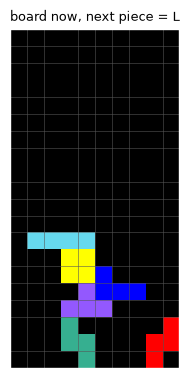

In [9]:
random.seed(7)
env.reset()
for _ in range(6):
    env.step(random.choice(list(env.get_next_states())), render=False)
print("next piece:", PIECE_NAMES[env.ind])
draw_board(env.board, title=f"board now, next piece = {PIECE_NAMES[env.ind]}");

In [10]:
next_steps = env.get_next_states()      # dict: action -> 4 features of the board after that action
print("number of possible actions:", len(next_steps))
for action, feats in list(next_steps.items())[:5]:
    print("action (x, rotation) =", action, "-> features", feats.tolist())

number of possible actions: 34
action (x, rotation) = (0, 0) -> features [0.0, 37.0, 10.0, 65.0]
action (x, rotation) = (1, 0) -> features [0.0, 29.0, 19.0, 57.0]
action (x, rotation) = (2, 0) -> features [0.0, 29.0, 19.0, 57.0]
action (x, rotation) = (3, 0) -> features [0.0, 31.0, 19.0, 59.0]
action (x, rotation) = (4, 0) -> features [0.0, 34.0, 19.0, 62.0]


The number of actions changes with the piece. The O piece has 1 useful rotation.
The S, Z and I pieces have 2. The T, L and J pieces have 4.

The board after an action is an **afterstate**. Below are the first 10 afterstates.
Random moves make many holes. To check a count, look at one column: count the empty cells under its top block.
In Lesson 2, the network gives a value to each afterstate, and the agent takes the best one.

---

🇻🇳 Số nước đi thay đổi theo loại mảnh. Mảnh O có 1 kiểu xoay có ích. Mảnh S, Z và I có 2. Mảnh T, L và J có 4.

Bàn chơi sau một nước đi là một **afterstate** (trạng thái sau nước đi). Bên dưới là 10 afterstate đầu tiên.
Nước đi ngẫu nhiên tạo ra nhiều lỗ. Để kiểm tra một con số, hãy nhìn một cột: đếm các ô trống nằm dưới khối cao nhất của cột đó.
Ở Bài 2, mạng nơ-ron cho mỗi afterstate một giá trị, và agent chọn afterstate tốt nhất.

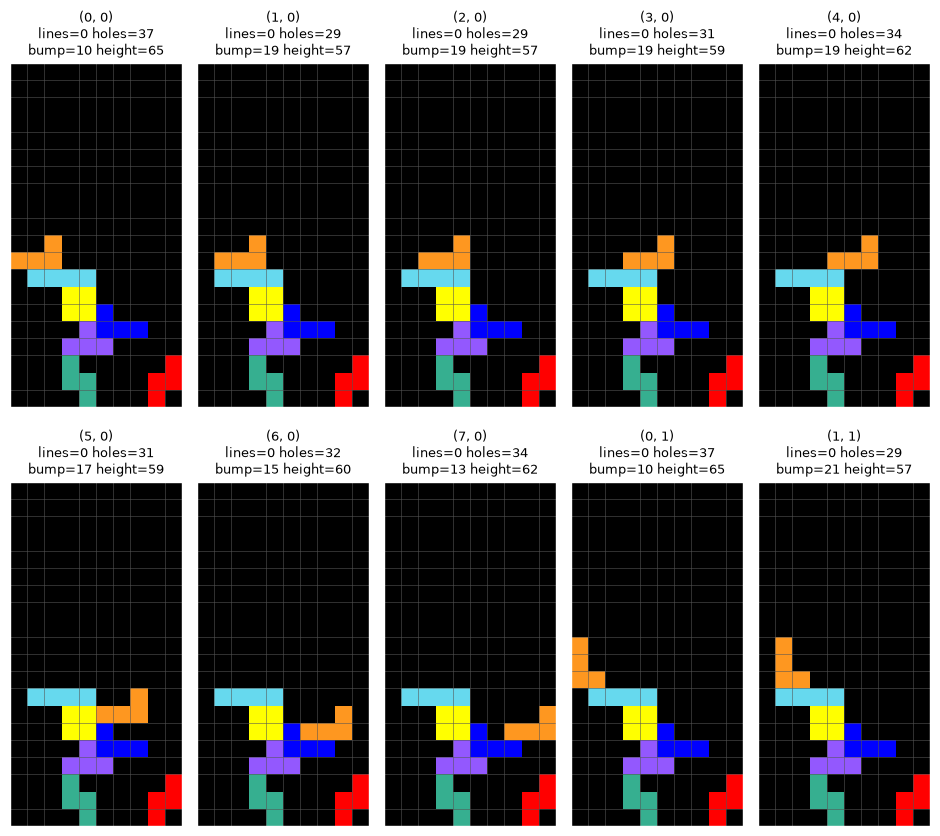

In [11]:
options = afterstates(env)
draw_boards([o["board"] for o in options[:10]],
            titles=[f"{o['action']}\n" + features_text(o["features"]) for o in options[:10]], cols=5)

## Part 4 — The reward

After each move, `env.step()` returns a **reward**: `1 + lines_cleared² × 10`.

- **+1 for each piece** tells the agent: "stay alive".
- **lines² (squared)** tells the agent: "clear many lines at the same time".

---

**🇻🇳 Phần 4 — Phần thưởng (reward)**

Sau mỗi nước đi, `env.step()` trả về một **reward** (phần thưởng): `1 + lines_cleared² × 10`.

- **+1 cho mỗi mảnh** nói với agent: "hãy sống sót".
- **lines² (bình phương)** nói với agent: "hãy xóa nhiều hàng cùng lúc".

In [12]:
for lines in range(5):
    print(f"clear {lines} lines -> reward {1 + lines ** 2 * 10}")

clear 0 lines -> reward 1
clear 1 lines -> reward 11
clear 2 lines -> reward 41
clear 3 lines -> reward 91
clear 4 lines -> reward 161


Now we play one full game with random moves and look at the rewards.

Note: at game over, the code subtracts 2 from `env.score`. But `env.step()` does **not** return that −2,
so the agent never sees it. The real penalty for game over: the agent gets no more future rewards (Lesson 3).

---

🇻🇳 Bây giờ ta chơi trọn một ván bằng nước đi ngẫu nhiên và xem các phần thưởng.

Lưu ý: khi thua (game over), code trừ 2 khỏi `env.score`. Nhưng `env.step()` **không** trả về −2 đó,
nên agent không bao giờ thấy nó. Hình phạt thật sự khi thua: agent không nhận thêm phần thưởng nào trong tương lai (Bài 3).

In [13]:
random.seed(1)
env.reset()
rewards, done = [], False
while not done:
    reward, done = env.step(random.choice(list(env.get_next_states())), render=False)
    rewards.append(reward)
print("rewards, one per piece:", rewards)
print("sum of rewards:", sum(rewards), "| env.score:", env.score, "(includes the -2 at game over)")

rewards, one per piece: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
sum of rewards: 19 | env.score: 17 (includes the -2 at game over)


## Part 5 — A baseline: the random agent

A **baseline** is a simple result that we compare against. A good agent must do much better than random.

---

**🇻🇳 Phần 5 — Mốc so sánh (baseline): agent ngẫu nhiên**

**Baseline** là một kết quả đơn giản để ta so sánh. Một agent tốt phải làm tốt hơn ngẫu nhiên rất nhiều.

In [14]:
print("random agent, average of 20 games:", evaluate(random_policy, games=20))

random agent, average of 20 games: {'pieces': 17.7, 'lines': 0.0, 'score': 15.7}


## Summary

- The board is a 20 × 10 grid of numbers.
- The agent sees only **4 numbers**: lines cleared, holes, bumpiness, height.
- An action is a final place `(x, rotation)`. The board after it is an **afterstate**.
- The reward is `1 + lines² × 10`. A random agent places about 18 pieces and clears almost no lines.

### Check your understanding

<details><summary>1. Why does the agent see 4 numbers, not the 200 cells?</summary>
A small input makes the problem small. A tiny network can learn it in minutes. The trade-off:
a person chose the 4 features, so the agent does not discover them itself.
</details>

<details><summary>2. Does the agent press "left" and "rotate"?</summary>
No. The game lists every final place. The agent chooses one final place directly.
</details>

<details><summary>3. Why is the reward for 4 lines (161) much more than 4 × the reward for 1 line (44)?</summary>
The square (lines²) makes multi-line clears very valuable, so the agent learns to prepare them.
</details>

**Next:** `02_network_and_decisions.ipynb` — the neural network that gives a value to each afterstate.

---

**🇻🇳 Tóm tắt**

- Bàn chơi là một lưới số 20 × 10.
- Agent chỉ nhìn thấy **4 con số**: số hàng xóa được, số lỗ, độ gồ ghề, chiều cao.
- Một nước đi là một vị trí cuối cùng `(x, rotation)`. Bàn chơi sau nước đi đó là một **afterstate**.
- Phần thưởng là `1 + lines² × 10`. Agent ngẫu nhiên đặt khoảng 18 mảnh và gần như không xóa được hàng nào.

**🇻🇳 Kiểm tra hiểu bài**

<details><summary>1. Tại sao agent nhìn 4 con số, mà không nhìn 200 ô?</summary>
Đầu vào nhỏ làm bài toán nhỏ. Một mạng nơ-ron rất nhỏ có thể học nó trong vài phút. Đánh đổi:
con người chọn 4 đặc trưng này, nên agent không tự khám phá ra chúng.
</details>

<details><summary>2. Agent có bấm "trái" và "xoay" không?</summary>
Không. Trò chơi liệt kê mọi vị trí cuối cùng. Agent chọn thẳng một vị trí cuối cùng.
</details>

<details><summary>3. Tại sao phần thưởng cho 4 hàng (161) lớn hơn nhiều so với 4 lần phần thưởng cho 1 hàng (44)?</summary>
Phép bình phương (lines²) làm cho việc xóa nhiều hàng cùng lúc rất có giá trị, nên agent học cách chuẩn bị cho chúng.
</details>

**Tiếp theo:** `02_network_and_decisions.ipynb` — mạng nơ-ron cho mỗi afterstate một giá trị.